# Measure and reconstruct a WALLE courtship signal in 3D

This notebook continues the `southpan1` example from `03_rectify_signal_video_walle.ipynb`. It detects luminous contours, groups detections into pulses, matches pulses between the rectified camera views, triangulates stereo pulse positions, and reconstructs the courtship trajectory in three dimensions.

The workflow follows the original WALL-E/Nextflow analysis and `WALLE initial results.ipynb`, but uses the OpenCV projection matrices produced by notebook 01 instead of estimating depth from field of view and a nominal baseline.

## 1. Imports and paths

Run this notebook with the `manta` conda kernel after notebooks 01 and 03. The generated measurement tables are written under `data/processed/`, which is excluded from Git.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = PROJECT_ROOT / 'data/processed/southwater2019'
LEFT_VIDEO = DATA_DIR / 'southpan1_rectified_left.mp4'
RIGHT_VIDEO = DATA_DIR / 'southpan1_rectified_right.mp4'
CALIBRATION_FILE = PROJECT_ROOT / 'data/processed/2019southwater_stereo_calibration.npz'

for label, path in [('left rectified video', LEFT_VIDEO), ('right rectified video', RIGHT_VIDEO),
                    ('stereo calibration', CALIBRATION_FILE)]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {label}: {path}')

print('Left video: ', LEFT_VIDEO)
print('Right video:', RIGHT_VIDEO)
print('Calibration:', CALIBRATION_FILE)

Left video:  /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_rectified_left.mp4
Right video: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_rectified_right.mp4
Calibration: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2019southwater_stereo_calibration.npz


## 2. Analysis parameters

These are the historical `southpan1` settings from `southwater2019_clips.csv` and `params_southwater2019_pan1.config`. Keeping them together makes it clear which choices affect detection, segmentation, and stereo matching.

In [2]:
# Bright-contour detection
CONTOUR_THRESHOLD = 130
MIN_CONTOUR_AREA = 0.1

# Join frame-level detections into a pulse
MAX_X_MOVEMENT = 10
MAX_Y_MOVEMENT = 10
MAX_FRAME_GAP = 2       # consecutive detections may differ by 1 or 2 frames
MIN_PULSE_FRAMES = 3

# Match a pulse between cameras
MAX_START_DIFFERENCE = 5
MAX_FINISH_DIFFERENCE = 5
MAX_VERTICAL_DIFFERENCE = 10
MAX_DISPARITY = 300

SAVE_TABLES = True
print({
    'threshold': CONTOUR_THRESHOLD, 'minimum contour area': MIN_CONTOUR_AREA,
    'minimum pulse frames': MIN_PULSE_FRAMES, 'maximum disparity': MAX_DISPARITY,
})

{'threshold': 130, 'minimum contour area': 0.1, 'minimum pulse frames': 3, 'maximum disparity': 300}


## 3. Detect luminous contours

For each frame and camera, pixels brighter than 130 are converted to a binary mask. Every connected contour larger than 0.1 px² is retained, matching the deliberately sensitive historical settings. Intensity measurements are calculated from the original grayscale pixels inside each contour.

In [3]:
def detect_video_contours(path, camera, threshold=CONTOUR_THRESHOLD, min_area=MIN_CONTOUR_AREA):
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f'OpenCV could not open {path}')
    fps = capture.get(cv2.CAP_PROP_FPS)
    rows = []
    frame_number = 0
    try:
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            _, mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
            contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
            for contour in contours:
                area = cv2.contourArea(contour)
                moments = cv2.moments(contour)
                if area <= min_area or moments['m00'] == 0:
                    continue
                contour_mask = np.zeros_like(gray)
                cv2.drawContours(contour_mask, [contour], -1, 255, -1)
                pixels = gray[contour_mask > 0]
                rows.append({
                    'camera': camera, 'frame': frame_number,
                    'x': moments['m10'] / moments['m00'],
                    'y': moments['m01'] / moments['m00'],
                    'area': area, 'min_intensity': float(pixels.min()),
                    'max_intensity': float(pixels.max()),
                    'mean_intensity': float(pixels.mean()),
                })
            frame_number += 1
    finally:
        capture.release()
    return pd.DataFrame(rows), fps, frame_number

left_detections, fps_left, frames_left = detect_video_contours(LEFT_VIDEO, 'left')
right_detections, fps_right, frames_right = detect_video_contours(RIGHT_VIDEO, 'right')
if frames_left != frames_right or not np.isclose(fps_left, fps_right):
    raise ValueError('Rectified clips do not have matching frame counts and frame rates.')
FPS = fps_left
detections = pd.concat([left_detections, right_detections], ignore_index=True)
print(f'{frames_left} synchronized frames at {FPS:.3f} fps')
print(detections.groupby('camera').size().rename('detections'))
display(detections.head())

350 synchronized frames at 29.970 fps
camera
left     76
right    44
Name: detections, dtype: int64


,camera,frame,x,y,area,min_intensity,max_intensity,mean_intensity
0,left,15,200.333333,20.666667,0.5,131.0,133.0,131.666667
1,left,16,200.333333,20.666667,0.5,131.0,133.0,131.666667
2,left,17,200.333333,20.666667,0.5,131.0,133.0,131.666667
3,left,18,200.333333,20.666667,0.5,131.0,133.0,131.666667
4,left,64,200.333333,20.666667,0.5,133.0,136.0,134.666667


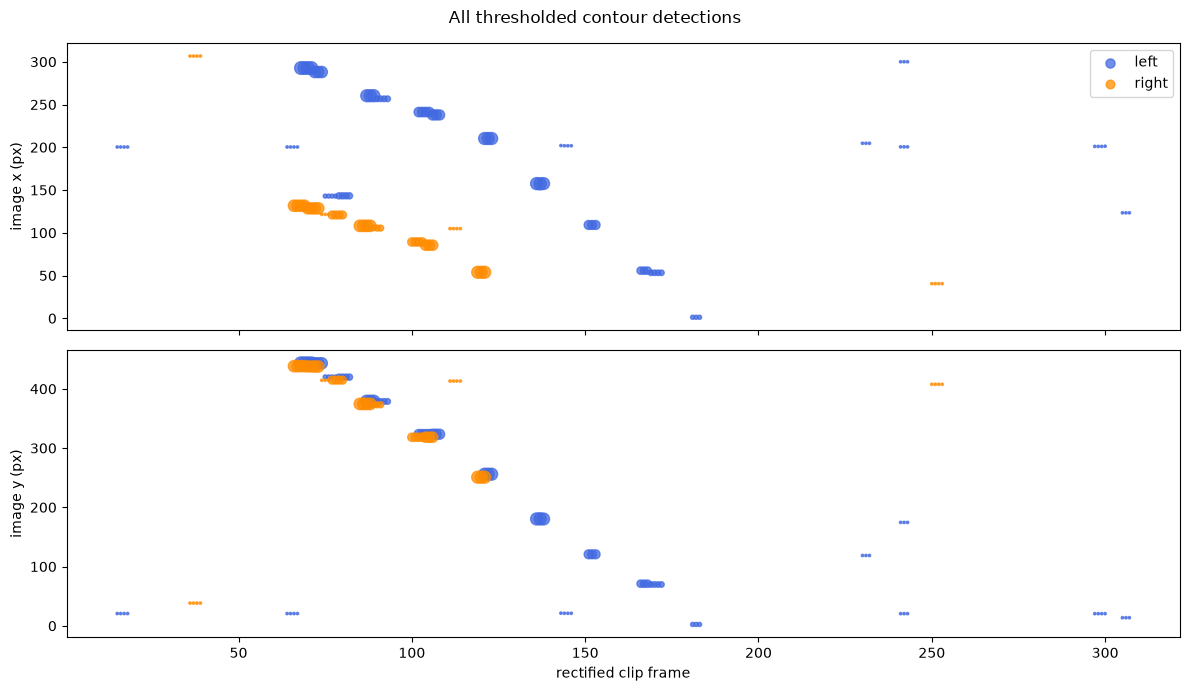

In [4]:
figure, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
colors = {'left': 'royalblue', 'right': 'darkorange'}
for camera, group in detections.groupby('camera'):
    axes[0].scatter(group['frame'], group['x'], s=np.maximum(group['area'], 3),
                    color=colors[camera], alpha=0.75, label=camera)
    axes[1].scatter(group['frame'], group['y'], s=np.maximum(group['area'], 3),
                    color=colors[camera], alpha=0.75, label=camera)
axes[0].set_ylabel('image x (px)')
axes[1].set_ylabel('image y (px)')
axes[1].set_xlabel('rectified clip frame')
axes[0].legend()
figure.suptitle('All thresholded contour detections')
plt.tight_layout()

## 4. Join detections into pulses

A detection joins an existing pulse track when it is sufficiently close in time, x, and y. Competing assignments are resolved from smallest movement to largest. Tracks shorter than three detected frames are treated as noise and omitted from the pulse table.

In [5]:
def track_camera_pulses(camera_detections, camera):
    records = camera_detections.sort_values(['frame', 'x', 'y']).to_dict('records')
    by_frame = {}
    for record in records:
        by_frame.setdefault(int(record['frame']), []).append(record)
    active, completed = [], []
    last_frame = int(camera_detections['frame'].max()) if len(camera_detections) else -1
    for frame in range(last_frame + MAX_FRAME_GAP + 1):
        frame_detections = by_frame.get(frame, [])
        candidates = []
        for track_index, track in enumerate(active):
            previous = track[-1]
            frame_gap = frame - previous['frame']
            if 0 < frame_gap <= MAX_FRAME_GAP:
                for detection_index, detection in enumerate(frame_detections):
                    dx = abs(detection['x'] - previous['x'])
                    dy = abs(detection['y'] - previous['y'])
                    if dx < MAX_X_MOVEMENT and dy < MAX_Y_MOVEMENT:
                        candidates.append((dx + dy + frame_gap, track_index, detection_index))
        used_tracks, used_detections = set(), set()
        for _, track_index, detection_index in sorted(candidates):
            if track_index in used_tracks or detection_index in used_detections:
                continue
            active[track_index].append(frame_detections[detection_index])
            used_tracks.add(track_index); used_detections.add(detection_index)
        for detection_index, detection in enumerate(frame_detections):
            if detection_index not in used_detections:
                active.append([detection])
        still_active = []
        for track in active:
            if frame - track[-1]['frame'] > MAX_FRAME_GAP:
                completed.append(track)
            else:
                still_active.append(track)
        active = still_active
    completed.extend(active)
    completed = [track for track in completed if len({row['frame'] for row in track}) >= MIN_PULSE_FRAMES]

    summaries, labeled = [], []
    for number, track in enumerate(sorted(completed, key=lambda rows: rows[0]['frame']), start=1):
        pulse = f'{camera[0]}p{number}'
        table = pd.DataFrame(track)
        table['pulse'] = pulse
        labeled.append(table)
        summaries.append({
            'camera': camera, 'pulse': pulse, 'start': int(table.frame.min()),
            'finish': int(table.frame.max()), 'detected_frames': table.frame.nunique(),
            'x': table.x.median(), 'y': table.y.median(),
            'max_intensity': table.max_intensity.max(),
            'mean_intensity': table.mean_intensity.mean(), 'mean_area': table.area.mean(),
        })
    return pd.concat(labeled, ignore_index=True) if labeled else pd.DataFrame(), pd.DataFrame(summaries)

left_labeled, left_pulses = track_camera_pulses(left_detections, 'left')
right_labeled, right_pulses = track_camera_pulses(right_detections, 'right')
labeled_detections = pd.concat([left_labeled, right_labeled], ignore_index=True)
pulses = pd.concat([left_pulses, right_pulses], ignore_index=True).sort_values(['start', 'camera'])
print(f'Retained {len(left_pulses)} left and {len(right_pulses)} right pulses')
display(pulses.round(2))

Retained 17 left and 8 right pulses


,camera,pulse,start,finish,detected_frames,x,y,max_intensity,mean_intensity,mean_area
0,left,lp1,15,18,4,200.33,20.67,133.0,131.67,0.50
17,right,rp1,36,39,4,306.67,38.33,138.0,134.33,0.50
1,left,lp2,64,67,4,200.33,20.67,136.0,134.67,0.50
18,right,rp2,66,73,8,130.08,438.02,188.0,160.91,66.38
2,left,lp3,68,74,7,292.67,443.20,185.0,163.15,75.71
19,right,rp3,74,80,7,120.84,414.67,171.0,144.53,19.71
3,left,lp4,75,82,8,143.06,419.94,176.0,148.14,14.25
20,right,rp4,85,91,7,108.13,374.54,181.0,154.29,46.86
4,left,lp5,87,93,7,256.70,378.69,183.0,155.92,41.86
21,right,rp5,100,106,7,89.25,318.29,185.0,157.48,44.57


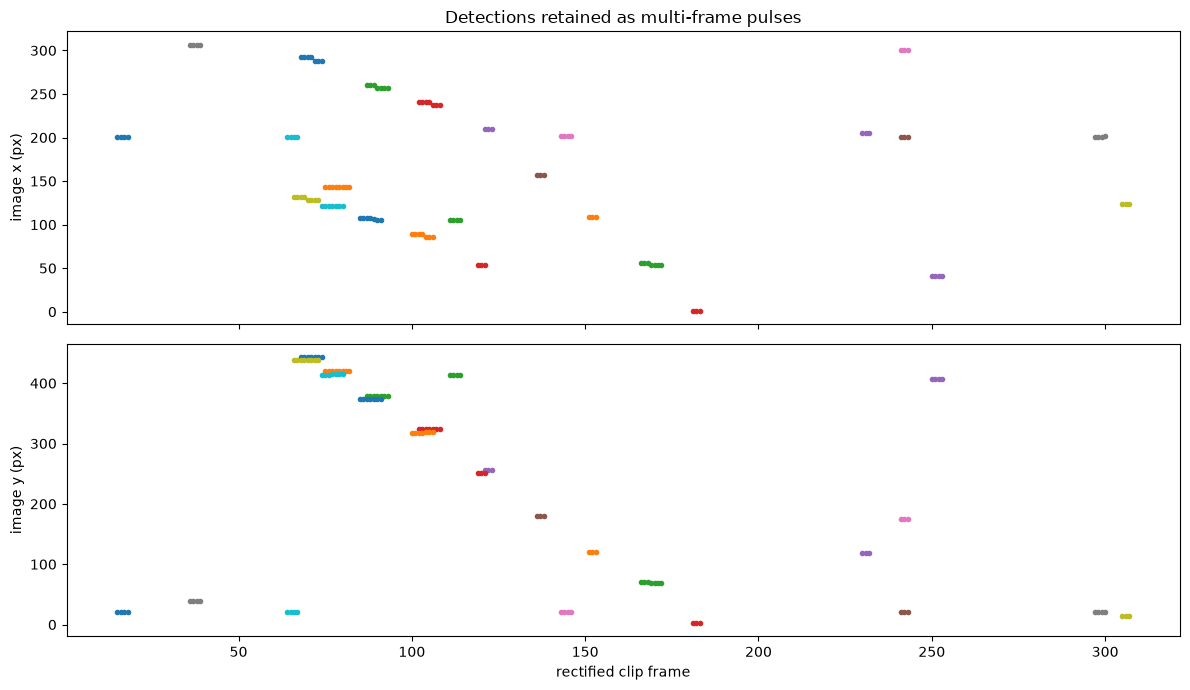

In [6]:
figure, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for pulse, group in labeled_detections.groupby('pulse'):
    camera = group.camera.iloc[0]
    axes[0].plot(group.frame, group.x, marker='o', markersize=3, linewidth=1, label=pulse)
    axes[1].plot(group.frame, group.y, marker='o', markersize=3, linewidth=1, label=pulse)
axes[0].set_ylabel('image x (px)')
axes[1].set_ylabel('image y (px)')
axes[1].set_xlabel('rectified clip frame')
axes[0].set_title('Detections retained as multi-frame pulses')
plt.tight_layout()

## 5. Match pulses between cameras

Candidate pulses must have similar start and finish frames, similar rectified y positions, and positive disparity below 300 px. Candidate matches are ranked by temporal and vertical disagreement; each pulse can be used only once. With these restrictive criteria, the `southpan1` candidates are unambiguous.

In [7]:
def match_stereo_pulses(left, right):
    candidates = []
    for _, left_pulse in left.iterrows():
        for _, right_pulse in right.iterrows():
            start_difference = abs(left_pulse.start - right_pulse.start)
            finish_difference = abs(left_pulse.finish - right_pulse.finish)
            vertical_difference = abs(left_pulse.y - right_pulse.y)
            disparity = left_pulse.x - right_pulse.x
            if (start_difference < MAX_START_DIFFERENCE
                    and finish_difference < MAX_FINISH_DIFFERENCE
                    and vertical_difference < MAX_VERTICAL_DIFFERENCE
                    and 0 < disparity < MAX_DISPARITY):
                cost = start_difference + finish_difference + vertical_difference
                candidates.append((cost, left_pulse, right_pulse, disparity,
                                   start_difference, finish_difference, vertical_difference))
    used_left, used_right, matches = set(), set(), []
    for candidate in sorted(candidates, key=lambda item: item[0]):
        cost, left_pulse, right_pulse, disparity, start_diff, finish_diff, vertical_diff = candidate
        if left_pulse.pulse in used_left or right_pulse.pulse in used_right:
            continue
        used_left.add(left_pulse.pulse); used_right.add(right_pulse.pulse)
        matches.append({
            'left_pulse': left_pulse.pulse, 'right_pulse': right_pulse.pulse,
            'start': int(min(left_pulse.start, right_pulse.start)),
            'finish': int(max(left_pulse.finish, right_pulse.finish)),
            'x_left': left_pulse.x, 'y_left': left_pulse.y,
            'x_right': right_pulse.x, 'y_right': right_pulse.y,
            'disparity': disparity, 'vertical_disparity': vertical_diff,
            'matching_cost': cost,
            'max_intensity': max(left_pulse.max_intensity, right_pulse.max_intensity),
            'mean_intensity': np.mean([left_pulse.mean_intensity, right_pulse.mean_intensity]),
            'mean_area': np.mean([left_pulse.mean_area, right_pulse.mean_area]),
        })
    matches = pd.DataFrame(matches).sort_values('start').reset_index(drop=True)
    matches.insert(0, 'stereo_pulse', [f'sp{i}' for i in range(1, len(matches) + 1)])
    return matches

stereo_pairs = match_stereo_pulses(left_pulses, right_pulses)
print(f'{len(stereo_pairs)} stereo pulse pairs')
display(stereo_pairs[[
    'stereo_pulse', 'left_pulse', 'right_pulse', 'start', 'finish',
    'disparity', 'vertical_disparity', 'matching_cost'
]].round(2))

5 stereo pulse pairs


,stereo_pulse,left_pulse,right_pulse,start,finish,disparity,vertical_disparity,matching_cost
0,sp1,lp3,rp2,66,74,162.59,5.17,8.17
1,sp2,lp4,rp3,74,82,22.22,5.28,8.28
2,sp3,lp5,rp4,85,93,148.56,4.15,8.15
3,sp4,lp6,rp5,100,108,151.92,5.05,9.05
4,sp5,lp7,rp7,119,123,156.46,5.07,9.07


## 6. Triangulate stereo pulses

`cv2.triangulatePoints` combines the paired rectified image coordinates with the saved left and right projection matrices. Coordinates are relative to the rectified left-camera coordinate system: x points right, y points down, and z points forward. Units inherit the checkerboard square-size units used in notebook 01 (currently millimetres).

In [8]:
with np.load(CALIBRATION_FILE) as archive:
    projection_left = archive['projection_left']
    projection_right = archive['projection_right']
    baseline = float(np.linalg.norm(archive['translation']))

def triangulate_pulse(row):
    point_left = np.array([[row.x_left], [row.y_left]], dtype=np.float64)
    point_right = np.array([[row.x_right], [row.y_right]], dtype=np.float64)
    homogeneous = cv2.triangulatePoints(
        projection_left, projection_right, point_left, point_right
    ).ravel()
    return homogeneous[:3] / homogeneous[3]

xyz = np.vstack([triangulate_pulse(row) for _, row in stereo_pairs.iterrows()])
stereo_points = stereo_pairs.copy()
stereo_points[['x_mm', 'y_down_mm', 'z_mm']] = xyz
stereo_points['vertical_mm'] = -stereo_points['y_down_mm']
stereo_points['duration_s'] = (stereo_points['finish'] - stereo_points['start'] + 1) / FPS
stereo_points['relative_brightness'] = stereo_points['mean_intensity'] * stereo_points['mean_area']
print(f'Calibration-derived baseline: {baseline:.2f} mm')
display(stereo_points[[
    'stereo_pulse', 'start', 'finish', 'disparity', 'vertical_disparity',
    'x_mm', 'vertical_mm', 'z_mm', 'duration_s', 'relative_brightness'
]].round(2))

Calibration-derived baseline: 100.91 mm


,stereo_pulse,start,finish,disparity,vertical_disparity,x_mm,vertical_mm,z_mm,duration_s,relative_brightness
0,sp1,66,74,162.59,5.17,-27.08,-118.23,345.85,0.30,11511.21
1,sp2,74,82,22.22,5.28,-878.05,-759.69,2531.96,0.30,2485.11
2,sp3,85,93,148.56,4.15,-54.07,-85.93,378.51,0.30,6879.96
3,sp4,100,108,151.92,5.05,-63.19,-46.96,370.14,0.30,7552.23
4,sp5,119,123,156.46,5.07,-81.29,-2.09,359.41,0.17,11881.93


## 7. Curate the focal courtship train

Stereo matching establishes geometrically plausible correspondence, but it does not prove that every flash belongs to the same animal. In the original analysis, the pulse interleaved near frame 80 had much smaller disparity and was interpreted as a separate, distant signal. The new reconstruction reaches the same conclusion: `sp2` triangulates much farther from the camera than the surrounding sequence.

This biological judgment is deliberately recorded as an explicit, editable exclusion rather than an invisible filter.

In [9]:
EXCLUDED_STEREO_PAIRS = {
    'sp2': 'Interleaved pulse with very small disparity and much greater reconstructed depth',
}

stereo_points['included'] = ~stereo_points.stereo_pulse.isin(EXCLUDED_STEREO_PAIRS)
stereo_points['curation_note'] = stereo_points.stereo_pulse.map(EXCLUDED_STEREO_PAIRS).fillna('focal courtship train')
courtship_3d = stereo_points.loc[stereo_points.included].copy().sort_values('start')
courtship_3d['observed_pulse'] = np.arange(1, len(courtship_3d) + 1)
courtship_3d['interpulse_interval_s'] = (
    courtship_3d.start - courtship_3d.finish.shift(1)
) / FPS
courtship_3d['vertical_displacement_mm'] = courtship_3d.vertical_mm.diff().abs()
courtship_3d['distance_3d_mm'] = np.sqrt(
    courtship_3d.x_mm.diff() ** 2
    + courtship_3d.y_down_mm.diff() ** 2
    + courtship_3d.z_mm.diff() ** 2
)
display(stereo_points[[
    'stereo_pulse', 'left_pulse', 'right_pulse', 'disparity', 'z_mm',
    'included', 'curation_note'
]].round(2))

,stereo_pulse,left_pulse,right_pulse,disparity,z_mm,included,curation_note
0,sp1,lp3,rp2,162.59,345.85,True,focal courtship train
1,sp2,lp4,rp3,22.22,2531.96,False,Interleaved pulse with very small disparity an...
2,sp3,lp5,rp4,148.56,378.51,True,focal courtship train
3,sp4,lp6,rp5,151.92,370.14,True,focal courtship train
4,sp5,lp7,rp7,156.46,359.41,True,focal courtship train


## 8. Plot the 3D courtship trajectory

Point size represents relative brightness (`mean intensity × mean contour area`). Numbers show temporal order. The connecting line is a visual aid between measured pulse locations; it is not a continuously tracked animal path.

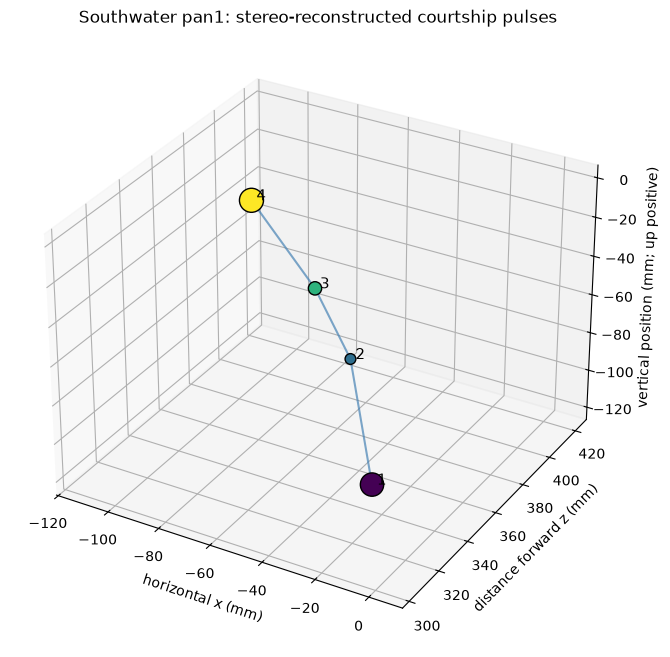

In [10]:
def set_axes_equal_3d(axis):
    limits = np.array([axis.get_xlim3d(), axis.get_ylim3d(), axis.get_zlim3d()])
    centers = limits.mean(axis=1)
    radius = 0.5 * np.max(limits[:, 1] - limits[:, 0])
    axis.set_xlim3d(centers[0] - radius, centers[0] + radius)
    axis.set_ylim3d(centers[1] - radius, centers[1] + radius)
    axis.set_zlim3d(centers[2] - radius, centers[2] + radius)

brightness = courtship_3d.relative_brightness.to_numpy()
marker_sizes = 60 + 240 * (brightness - brightness.min()) / max(np.ptp(brightness), 1)
figure = plt.figure(figsize=(10, 8))
axis = figure.add_subplot(111, projection='3d')
axis.plot(courtship_3d.x_mm, courtship_3d.z_mm, courtship_3d.vertical_mm,
          color='steelblue', linewidth=1.5, alpha=0.7)
axis.scatter(courtship_3d.x_mm, courtship_3d.z_mm, courtship_3d.vertical_mm,
             s=marker_sizes, c=courtship_3d.start, cmap='viridis',
             edgecolor='black', depthshade=False)
for _, row in courtship_3d.iterrows():
    axis.text(row.x_mm, row.z_mm, row.vertical_mm, f' {int(row.observed_pulse)}', fontsize=11)
axis.set_xlabel('horizontal x (mm)')
axis.set_ylabel('distance forward z (mm)')
axis.set_zlabel('vertical position (mm; up positive)')
axis.set_title('Southwater pan1: stereo-reconstructed courtship pulses')
set_axes_equal_3d(axis)
plt.show()

In [11]:
measurement_columns = [
    'observed_pulse', 'stereo_pulse', 'start', 'finish', 'duration_s',
    'interpulse_interval_s', 'x_mm', 'vertical_mm', 'z_mm',
    'vertical_displacement_mm', 'distance_3d_mm', 'relative_brightness',
]
display(courtship_3d[measurement_columns].round(3))

,observed_pulse,stereo_pulse,start,finish,duration_s,interpulse_interval_s,x_mm,vertical_mm,z_mm,vertical_displacement_mm,distance_3d_mm,relative_brightness
0,1,sp1,66,74,0.300,NaN,-27.079,-118.233,345.850,NaN,NaN,11511.214
2,2,sp3,85,93,0.300,0.367,-54.074,-85.928,378.511,32.304,53.283,6879.965
3,3,sp4,100,108,0.300,0.234,-63.190,-46.964,370.140,38.964,40.882,7552.229
4,4,sp5,119,123,0.167,0.367,-81.291,-2.095,359.413,44.869,49.558,11881.928


## 9. Save reproducible intermediate tables

Saving each stage makes thresholding, tracking, matching, triangulation, and biological curation independently inspectable. These generated TSV files are inputs for later comparative and statistical notebooks.

In [12]:
if SAVE_TABLES:
    outputs = {
        'southpan1_contour_detections.tsv': detections,
        'southpan1_segmented_pulses.tsv': pulses,
        'southpan1_stereo_points.tsv': stereo_points,
        'southpan1_courtship_measurements.tsv': courtship_3d[measurement_columns],
    }
    for filename, table in outputs.items():
        path = DATA_DIR / filename
        table.to_csv(path, sep='\t', index=False)
        print(f'Saved {len(table):>3} rows: {path}')

Saved 120 rows: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_contour_detections.tsv
Saved  25 rows: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_segmented_pulses.tsv
Saved   5 rows: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_stereo_points.tsv
Saved   4 rows: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_courtship_measurements.tsv


## Interpretation and next step

Only pulses visible in both cameras can be triangulated directly. The original biological reconstruction also retained pulses visible in one camera by assigning an estimated disparity from neighboring stereo pulses. That can be added next, but those inferred positions should remain explicitly distinguished from direct stereo measurements. After that, the same workflow can be generalized across Southwater and Hangman signals and compared with Rivers and Morin's aquarium measurements.